# Dataset B — Final six-model review

## tl;dr

Notebook này là cổng chỉ đọc cho so sánh cuối LR, RF, XGBoost, PlainMLP, RealMLP và TabMmini. Cả 6/6 final reporting packages đã PASS input/lineage gate. RQ1 paired bootstrap bao phủ đúng 15 model pairs × 10 accepted metrics, mỗi comparison dùng 1.000 shared Test replicate rows: 131 CI loại 0 và 19 CI chứa 0. Có 14/15 model pairs cho kết luận metric-specific theo hai hướng khác nhau, vì vậy không có tuyên bố model tốt nhất tuyệt đối.

## Context & Methods

Mỗi final model run xuất reporting package chuẩn gồm `model_summary.json`, `cv_fold_metrics.csv`, `rq1_metrics_long.csv`, `confusion_matrix.csv`, `calibration_curve.csv` và `artifact_index.json`. Notebook không huấn luyện, inference, chọn threshold, tạo bootstrap indices hay tính lại per-model bootstrap metrics; phần paired comparison ghép các metric rows đã accepted theo cùng replicate IDs và tính percentile 95% CI của paired differences.

In [1]:
from pathlib import Path
import importlib.util
import json
import os
import sys

import pandas as pd
import numpy as np
from IPython.display import Markdown, display

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'config/dataset_b/model_protocol_v1.yaml').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Cannot locate the Dataset B project root.')
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

reporting_module_path = PROJECT_ROOT / 'src/dataset_b/reporting/model_reporting.py'
reporting_spec = importlib.util.spec_from_file_location('_rq1_model_reporting', reporting_module_path)
reporting_contract = importlib.util.module_from_spec(reporting_spec)
reporting_spec.loader.exec_module(reporting_contract)
EXPECTED_REPORTING_FILES = reporting_contract.EXPECTED_REPORTING_FILES
FINAL_MODEL_KEYS = reporting_contract.FINAL_MODEL_KEYS

def validate_reporting_directory(reporting_dir):
    root = Path(reporting_dir)
    for filename in EXPECTED_REPORTING_FILES:
        if not (root / filename).is_file():
            raise RuntimeError(f'Reporting package is missing {filename}: {root}')
    summary = json.loads((root / 'model_summary.json').read_text(encoding='utf-8'))
    reporting_contract.validate_model_summary(summary, require_complete=True)
    model_key, run_id = str(summary['model_key']), str(summary['run_id'])
    frames = {}
    for filename, expected_columns in reporting_contract.REPORTING_CSV_COLUMNS.items():
        frame = pd.read_csv(root / filename)
        if tuple(frame.columns) != expected_columns or frame.empty:
            raise RuntimeError(f'Invalid reporting CSV contract: {root / filename}')
        if set(frame['model_key'].astype(str)) != {model_key} or set(frame['run_id'].astype(str)) != {run_id}:
            raise RuntimeError(f'Inconsistent reporting lineage: {root / filename}')
        frames[filename] = frame
    if sorted(frames['cv_fold_metrics.csv']['fold'].astype(int).tolist()) != [1, 2, 3, 4, 5]:
        raise RuntimeError('CV reporting rows must cover folds 1-5 exactly once.')
    if set(frames['rq1_metrics_long.csv']['metric'].astype(str)) != reporting_contract.REQUIRED_RQ1_METRICS:
        raise RuntimeError('RQ1 reporting metrics differ from the accepted ten-metric contract.')
    artifact_index = json.loads((root / 'artifact_index.json').read_text(encoding='utf-8'))
    if artifact_index.get('schema_version') != reporting_contract.REPORTING_SCHEMA_VERSION or artifact_index.get('model_key') != model_key or artifact_index.get('run_id') != run_id:
        raise RuntimeError('Artifact-index identity differs from the reporting package.')
    if not isinstance(artifact_index.get('artifacts'), list) or not artifact_index['artifacts']:
        raise RuntimeError('Artifact index is empty.')
    return summary

def _current_prediction_path(model_key):
    run_root = (PROJECT_ROOT / MODEL_SUMMARY_PATHS[model_key]).parent.parent
    candidates = [run_root / 'test/test_predictions.csv', run_root / 'test_evaluation/test_predictions.csv']
    path = next((candidate for candidate in candidates if candidate.is_file()), None)
    if path is None:
        raise FileNotFoundError(f'Missing current-checkout Test predictions for {model_key}.')
    return path

def validate_cross_model_summaries(candidate_summaries):
    if len(candidate_summaries) != len(FINAL_MODEL_KEYS):
        raise RuntimeError('Exactly six model summaries are required.')
    for summary in candidate_summaries:
        reporting_contract.validate_model_summary(summary, require_complete=True)
    keys = [str(summary['model_key']) for summary in candidate_summaries]
    if len(set(keys)) != len(keys) or set(keys) != set(FINAL_MODEL_KEYS):
        raise RuntimeError('The six-model summary roster differs.')
    expected_ids = None
    for model_key in FINAL_MODEL_KEYS:
        ids = tuple(pd.read_csv(_current_prediction_path(model_key), usecols=['record_id'], dtype={'record_id': str}, keep_default_na=False)['record_id'])
        if len(ids) != 43996 or len(set(ids)) != 43996:
            raise RuntimeError(f'Test IDs are incomplete or duplicated for {model_key}.')
        if expected_ids is None:
            expected_ids = ids
        elif ids != expected_ids:
            raise RuntimeError('Test membership/order lineage differs across models.')
    with np.load(PROJECT_ROOT / 'artifacts/dataset_b/rq1_test_bootstrap_indices.npz', allow_pickle=False) as payload:
        indices = np.asarray(payload['indices'])
    if indices.shape != (1000, 43996) or indices.dtype != np.int32:
        raise RuntimeError('Locked bootstrap indices shape/dtype differs.')

MODEL_SUMMARY_PATHS = {model: None for model in FINAL_MODEL_KEYS}
MODEL_SUMMARY_PATHS['lr'] = 'artifacts/dataset_b/lr/final/lr_final_15f_20261002_01/reporting/model_summary.json'
MODEL_SUMMARY_PATHS['rf'] = 'artifacts/dataset_b/rf/final/rf_final_15f_20261002_01/reporting/model_summary.json'
MODEL_SUMMARY_PATHS['xgboost'] = 'artifacts/dataset_b/xgboost/final/xgb_final_15f_20261003_01/reporting/model_summary.json'
MODEL_SUMMARY_PATHS['plain_mlp'] = 'artifacts/dataset_b/plain_mlp/final/plain_mlp_final_15f_20261004_03/reporting/model_summary.json'
MODEL_SUMMARY_PATHS['realmlp'] = 'artifacts/dataset_b/realmlp/final/realmlp_final_15f_20261004_01/reporting/model_summary.json'
MODEL_SUMMARY_PATHS['tabmmini'] = 'artifacts/dataset_b/tabmmini/final/tabmmini_final_15f_20261004_01/reporting/model_summary.json'
print('Reporting contract files:', ', '.join(EXPECTED_REPORTING_FILES))

Reporting contract files: model_summary.json, cv_fold_metrics.csv, rq1_metrics_long.csv, confusion_matrix.csv, calibration_curve.csv, artifact_index.json


### Key Assumptions

- Chỉ đường dẫn tới `final/<run_id>/reporting/model_summary.json` được phép điền.
- Working, legacy 12-feature và incomplete summaries không đủ điều kiện so sánh.
- Readiness kiểm tra `reporting_status` cùng publication marker (`FROZEN` hoặc `COMPLETED`). Nếu có `final_review.json` riêng, trạng thái direct review được hiển thị độc lập.
- Trường generation-time bên trong từng model summary không thay thế publication marker hoặc separate direct review.
- CI riêng từng model không tự động chứng minh chênh lệch giữa model có ý nghĩa thống kê.

## Data

### Reporting readiness

In [2]:
summaries = []
readiness_rows = []
for model_key in FINAL_MODEL_KEYS:
    configured = MODEL_SUMMARY_PATHS[model_key]
    if configured is None:
        readiness_rows.append({'model_key': model_key, 'reporting_summary': 'NOT_CONFIGURED', 'reporting_status': 'PENDING', 'publication_marker': 'MISSING', 'separate_direct_review': 'NOT_AVAILABLE', 'eligible': False})
        continue
    path = PROJECT_ROOT / configured
    if not path.is_file():
        readiness_rows.append({'model_key': model_key, 'reporting_summary': str(configured), 'reporting_status': 'MISSING', 'publication_marker': 'MISSING', 'separate_direct_review': 'NOT_AVAILABLE', 'eligible': False})
        continue
    summary = validate_reporting_directory(path.parent)
    run_root = path.parent.parent
    publication_marker = 'FROZEN' if (run_root / 'FROZEN').is_file() else ('COMPLETED' if (run_root / 'COMPLETED').is_file() else 'MISSING')
    direct_review_path = run_root / 'final_review.json'
    separate_direct_review = json.loads(direct_review_path.read_text(encoding='utf-8')).get('status', 'INVALID') if direct_review_path.is_file() else 'NOT_SEPARATE'
    reporting_status = summary.get('reporting_status', 'INVALID')
    eligible = reporting_status == 'COMPLETE' and publication_marker in {'FROZEN', 'COMPLETED'}
    if eligible:
        summaries.append(summary)
    readiness_rows.append({'model_key': model_key, 'reporting_summary': str(configured), 'reporting_status': reporting_status, 'publication_marker': publication_marker, 'separate_direct_review': separate_direct_review, 'eligible': eligible})

readiness = pd.DataFrame(readiness_rows)
display(readiness)

,model_key,reporting_summary,reporting_status,publication_marker,separate_direct_review,eligible
0,lr,artifacts/dataset_b/lr/final/lr_final_15f_2026...,COMPLETE,FROZEN,NOT_SEPARATE,True
1,rf,artifacts/dataset_b/rf/final/rf_final_15f_2026...,COMPLETE,FROZEN,NOT_SEPARATE,True
2,xgboost,artifacts/dataset_b/xgboost/final/xgb_final_15...,COMPLETE,FROZEN,NOT_SEPARATE,True
3,plain_mlp,artifacts/dataset_b/plain_mlp/final/plain_mlp_...,COMPLETE,FROZEN,NOT_SEPARATE,True
4,realmlp,artifacts/dataset_b/realmlp/final/realmlp_fina...,COMPLETE,FROZEN,PASS,True
5,tabmmini,artifacts/dataset_b/tabmmini/final/tabmmini_fi...,COMPLETE,FROZEN,PASS,True


## Results

Cross-model tables và charts chỉ được mở sau khi gate dưới đây PASS.

In [3]:
comparison_ready = False
if len(summaries) == len(FINAL_MODEL_KEYS):
    validate_cross_model_summaries(summaries)
    comparison_ready = True

if comparison_ready:
    display(Markdown('**PASS:** Sáu final reporting packages đã sẵn sàng cho tổng hợp.'))
else:
    display(Markdown(f'**PENDING:** mới có {len(summaries)}/{len(FINAL_MODEL_KEYS)} final reporting packages đủ điều kiện; chưa mở so sánh.'))

**PASS:** Sáu final reporting packages đã sẵn sàng cho tổng hợp.

### Visual contract sau khi gate PASS

1. CV ROC-AUC: fold dot plot theo model, cùng scale.
2. RQ1 metrics: small-multiple forest plots với point estimate và CI 95%.
3. Calibration: small multiples cùng trục và đường lý tưởng.
4. Confusion/recall: bảng và heatmap chuẩn hóa.
5. Threshold và timing: bảng; chỉ so sánh timing khi định nghĩa tương đương.

Không dùng radar chart, không xếp hạng bằng metric không cùng hướng và không suy ra statistical significance từ CI riêng lẻ.

## Takeaways

Cả sáu model đã được nối vào đúng final reporting packages và paired-bootstrap gate đã PASS cho 15/15 model pairs. Bằng chứng được kết luận riêng theo từng metric: 131/150 CI loại 0, 19/150 CI chứa 0. Năm hàng calibration-slope có RF vẫn dùng 1.000 paired rows nhưng có 998 paired differences hữu hạn do hai RF payloads đã invalid trong frozen artifact. Kết quả không cho phép tuyên bố model tốt nhất tuyệt đối và không thay đổi lựa chọn XGBoost/RealMLP cho RQ4 dựa trên fairness.

In [4]:
if not comparison_ready:
    raise RuntimeError("Gates chưa PASS, không thể load artifacts và thực hiện so sánh.")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

# Setup visualization style
plt.style.use('default')
sns.set_theme(style="whitegrid")
colors = sns.color_palette("husl", len(FINAL_MODEL_KEYS))
model_colors = dict(zip(FINAL_MODEL_KEYS, colors))

cv_list = []
rq1_list = []
calib_list = []
conf_list = []
summary_list = []

for model_key in FINAL_MODEL_KEYS:
    if not readiness[readiness['model_key'] == model_key]['eligible'].iloc[0]:
        continue
    path = PROJECT_ROOT / MODEL_SUMMARY_PATHS[model_key]
    rep_dir = path.parent
    
    cv_list.append(pd.read_csv(rep_dir / 'cv_fold_metrics.csv'))
    rq1_list.append(pd.read_csv(rep_dir / 'rq1_metrics_long.csv'))
    calib_list.append(pd.read_csv(rep_dir / 'calibration_curve.csv'))
    conf_list.append(pd.read_csv(rep_dir / 'confusion_matrix.csv'))
    
    with open(path, 'r', encoding='utf-8') as f:
        s = json.load(f)
        summary_list.append(s)

df_cv = pd.concat(cv_list, ignore_index=True)
df_rq1 = pd.concat(rq1_list, ignore_index=True)
df_calib = pd.concat(calib_list, ignore_index=True)
df_conf = pd.concat(conf_list, ignore_index=True)


### 1. CV ROC-AUC

C:\Users\Dan\AppData\Local\Temp\ipykernel_10512\1776863899.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(new_labels)


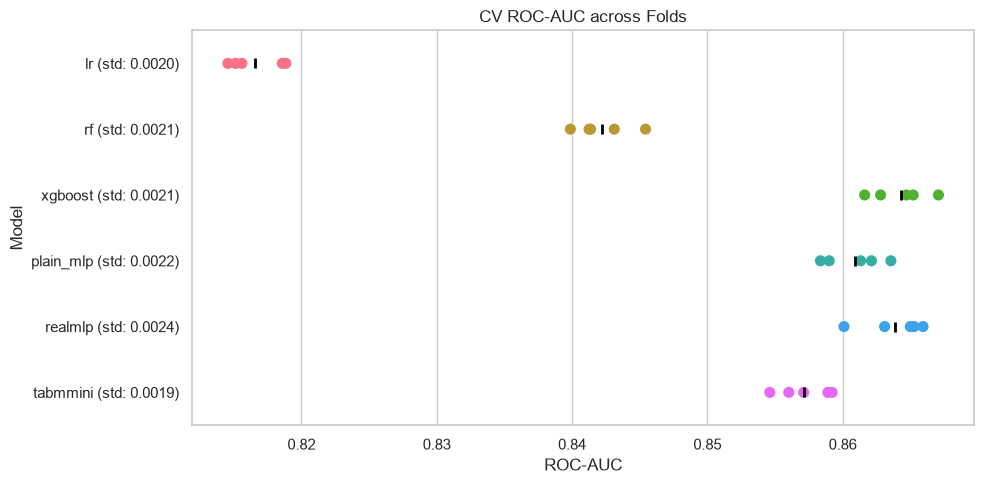

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

# 1. Vẽ stripplot phân tán ban đầu
sns.stripplot(data=df_cv, x='roc_auc', y='model_key', hue='model_key', palette=model_colors,
              size=8, jitter=False, ax=ax, legend=False, zorder=1)

# 2. Thêm pointplot hiển thị giá trị mean
sns.pointplot(data=df_cv, x='roc_auc', y='model_key', estimator=np.mean,
              errorbar=None, color='black', markers='|', linestyle='none', ax=ax, zorder=2)

# 3. Tính std và cập nhật nhãn trục Y
# Gọi draw() để đảm bảo yticklabels được render và lấy được text
fig.canvas.draw()
cv_std = df_cv.groupby('model_key')['roc_auc'].std()
new_labels = []
for tick in ax.get_yticklabels():
    mk = tick.get_text()
    if mk in cv_std:
        new_labels.append(f"{mk} (std: {cv_std[mk]:.4f})")
    else:
        new_labels.append(mk)
ax.set_yticklabels(new_labels)

ax.set_title('CV ROC-AUC across Folds')
ax.set_xlabel('ROC-AUC')
ax.set_ylabel('Model')
plt.tight_layout()
plt.show()


### 2. RQ1 metrics (forest plots)

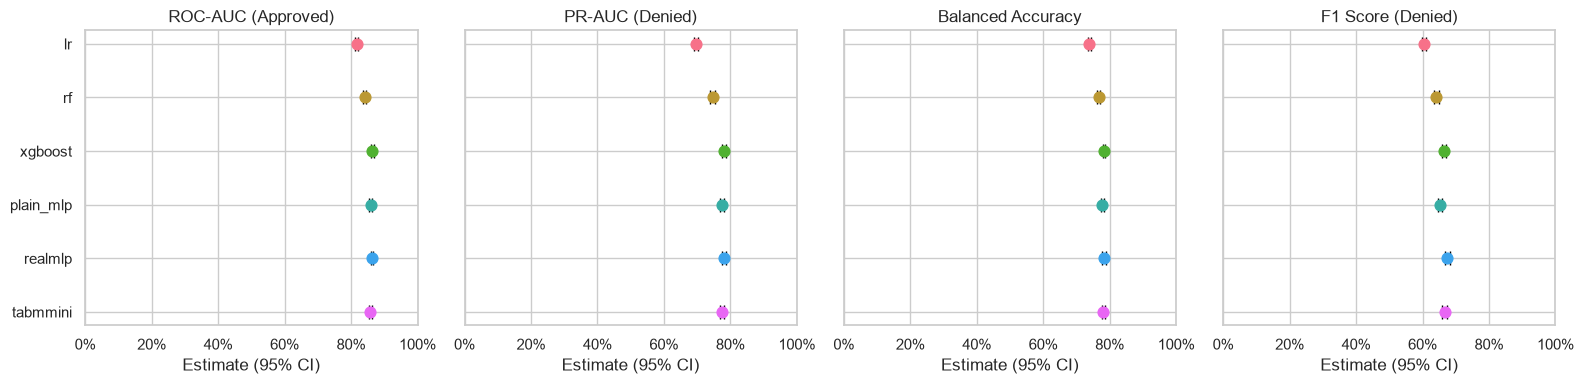

In [6]:
from matplotlib.ticker import PercentFormatter

plot_metrics = ['roc_auc_approved', 'average_precision_denied', 'balanced_accuracy', 'f1_denied']
metric_labels = {
    'roc_auc_approved': 'ROC-AUC (Approved)',
    'average_precision_denied': 'PR-AUC (Denied)',
    'balanced_accuracy': 'Balanced Accuracy',
    'f1_denied': 'F1 Score (Denied)'
}

df_rq1_sub = df_rq1[df_rq1['metric'].isin(plot_metrics)].copy()

fig, axes = plt.subplots(1, len(plot_metrics), figsize=(16, 4), sharex=True, sharey=True)

for ax, metric in zip(axes, plot_metrics):
    sub = df_rq1_sub[df_rq1_sub['metric'] == metric].copy()
    sub['model_key'] = pd.Categorical(sub['model_key'], categories=FINAL_MODEL_KEYS, ordered=True)
    sub = sub.sort_values('model_key', ascending=False)
    
    y_pos = np.arange(len(sub))
    ax.errorbar(sub['estimate'], y_pos, 
                xerr=[sub['estimate'] - sub['ci_low'], sub['ci_high'] - sub['estimate']],
                fmt='none', color='black', capsize=5, zorder=1)
    
    for i, m in enumerate(sub['model_key']):
        if pd.notna(m):
            ax.scatter(sub['estimate'].iloc[i], i, color=model_colors[m], s=60, zorder=2)
        
    ax.set_yticks(y_pos)
    ax.set_yticklabels(sub['model_key'])
    ax.set_title(metric_labels.get(metric, metric))
    ax.set_xlim([0.0, 1.0])
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=0))
    ax.set_xlabel('Estimate (95% CI)')

plt.tight_layout()
plt.show()


### 3. Calibration curves

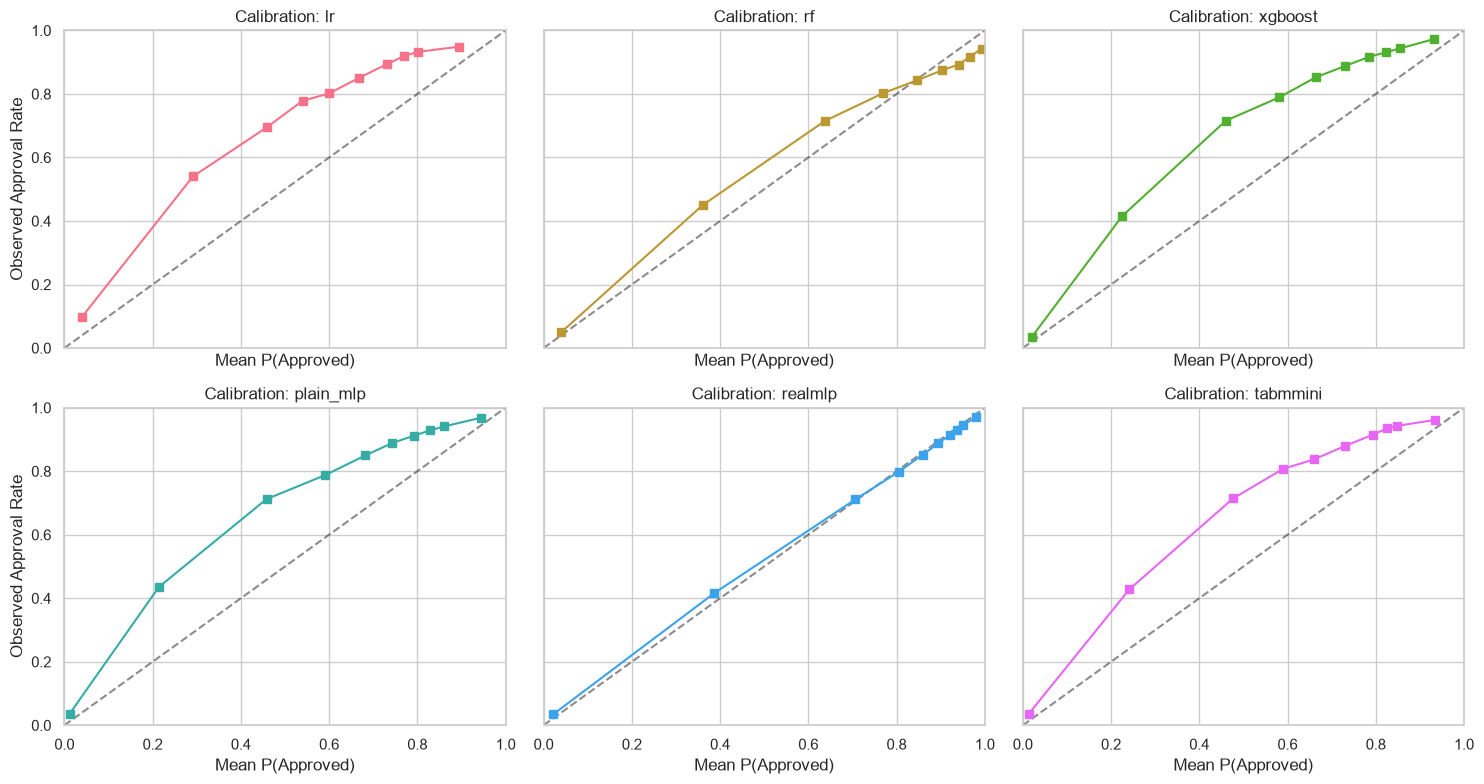

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
axes = axes.flatten()

for i, model_key in enumerate(FINAL_MODEL_KEYS):
    ax = axes[i]
    if model_key not in df_calib['model_key'].values:
        ax.set_visible(False)
        continue
        
    sub = df_calib[df_calib['model_key'] == model_key]
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Perfectly calibrated')
    ax.plot(sub['mean_p_approved'], sub['observed_approval_rate'], 's-', 
            color=model_colors[model_key], label=model_key)
    
    ax.set_title(f'Calibration: {model_key}')
    ax.set_xlabel('Mean P(Approved)')
    if i % 3 == 0:
        ax.set_ylabel('Observed Approval Rate')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()


### 4. Confusion matrix & Recall

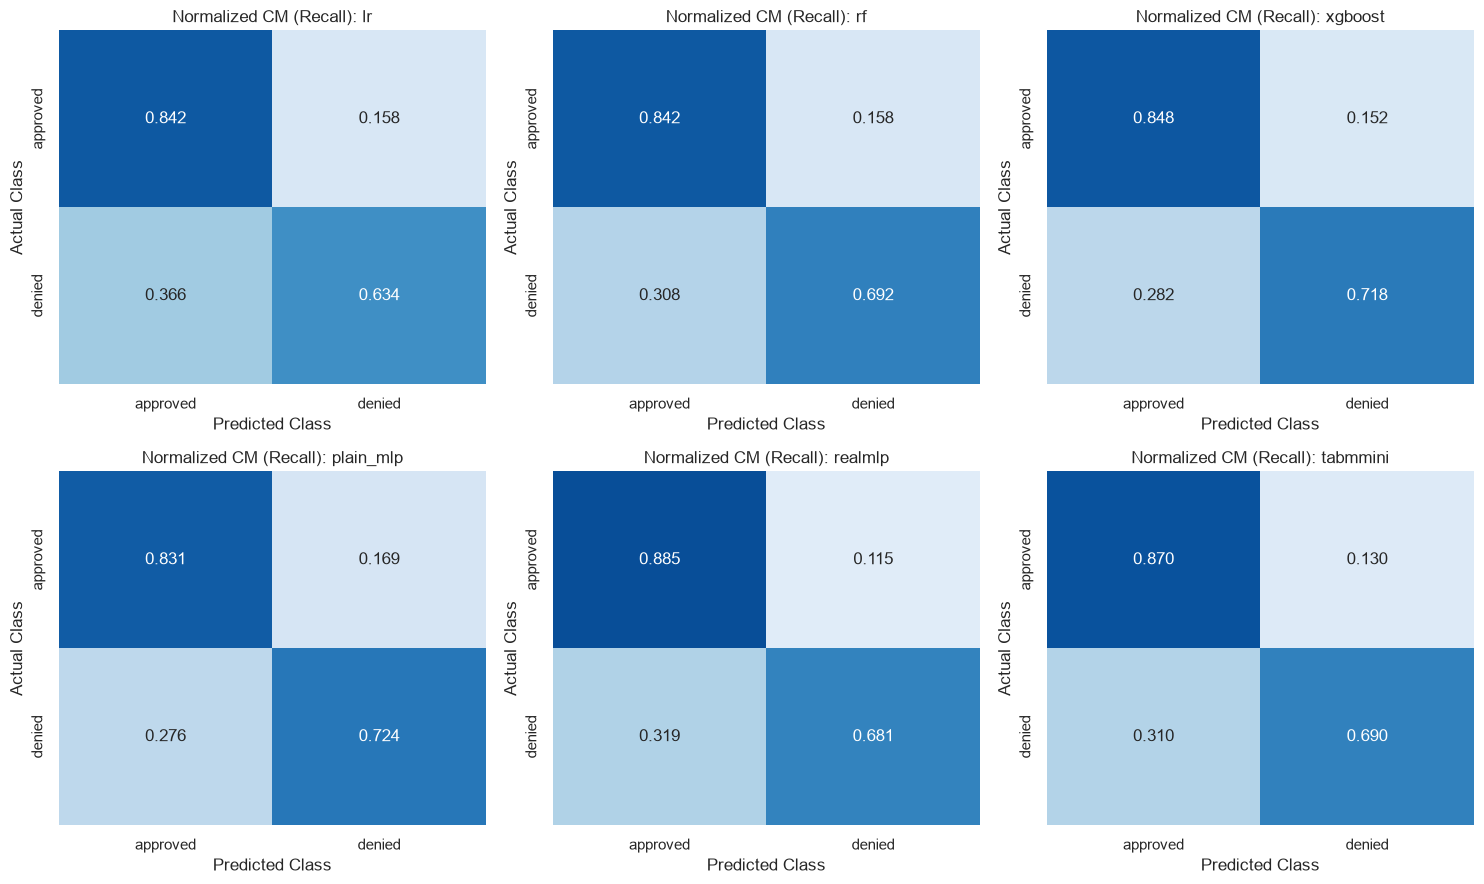

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()
class_order = ['approved', 'denied']

for i, model_key in enumerate(FINAL_MODEL_KEYS):
    ax = axes[i]
    if model_key not in df_conf['model_key'].values:
        ax.set_visible(False)
        continue
        
    sub_conf = df_conf[df_conf['model_key'] == model_key].copy()
    sub_conf['actual_class'] = pd.Categorical(sub_conf['actual_class'], categories=class_order, ordered=True)
    sub_conf['predicted_class'] = pd.Categorical(sub_conf['predicted_class'], categories=class_order, ordered=True)
    cm = sub_conf.pivot(index='actual_class', columns='predicted_class', values='count')
    cm = cm.reindex(index=class_order, columns=class_order, fill_value=0).fillna(0)
    cm_norm = cm.div(cm.sum(axis=1), axis=0)
    
    sns.heatmap(cm_norm, annot=True, fmt='.3f', cmap='Blues', ax=ax, cbar=False, vmin=0, vmax=1)
    ax.set_title(f'Normalized CM (Recall): {model_key}')
    ax.set_ylabel('Actual Class')
    ax.set_xlabel('Predicted Class')

plt.tight_layout()
plt.show()


### 5. Threshold and Timing

In [9]:
timing_records = []
for model_key in FINAL_MODEL_KEYS:
    if model_key not in df_cv['model_key'].values:
        continue
        
    sub_cv = df_cv[df_cv['model_key'] == model_key]
    fit_time = sub_cv['fit_seconds'].mean()
    predict_timing_recorded = not sub_cv['predict_seconds'].eq(0).all()
    pred_time = sub_cv['predict_seconds'].mean() if predict_timing_recorded else np.nan
    
    summary = next((s for s in summary_list if s.get('model_key') == model_key), {})
    threshold = summary.get('selected_threshold')
    if threshold is None:
        threshold = summary.get('validation', {}).get('threshold')
        
    timing_records.append({
        'model_key': model_key,
        'mean_fit_seconds': fit_time,
        'mean_predict_seconds': pred_time,
        'predict_timing_status': 'recorded' if predict_timing_recorded else 'not recorded',
        'threshold': threshold
    })

timing_df = pd.DataFrame(timing_records).rename(columns={
    'mean_fit_seconds': 'mean_cv_fit_seconds',
    'mean_predict_seconds': 'mean_cv_predict_seconds',
    'threshold': 'selected_threshold',
})

timing_display = timing_df.copy()
for column in ['mean_cv_fit_seconds', 'mean_cv_predict_seconds', 'selected_threshold']:
    timing_display[column] = timing_display[column].map(
        lambda value: f'{value:.3f}' if pd.notna(value) else '—'
    )

display(timing_display)


,model_key,mean_cv_fit_seconds,mean_cv_predict_seconds,predict_timing_status,selected_threshold
0,lr,0.770,—,not recorded,0.493
1,rf,326.861,1.122,recorded,0.712
2,xgboost,0.558,0.014,recorded,0.525
3,plain_mlp,44.258,0.598,recorded,0.543
4,realmlp,505.543,—,not recorded,0.726
5,tabmmini,284.840,0.376,recorded,0.508


In [10]:
comparison_metrics = {
    'roc_auc_approved': 'ROC-AUC',
    'average_precision_denied': 'AP Denied',
    'f1_denied': 'F1 Denied',
    'balanced_accuracy': 'BA',
    'brier_score_approved': 'Brier score',
}

metric_rows = df_rq1[df_rq1['metric'].isin(comparison_metrics)].copy()
expected_pairs = pd.MultiIndex.from_product(
    [FINAL_MODEL_KEYS, comparison_metrics], names=['model_key', 'metric']
)
observed_pairs = pd.MultiIndex.from_frame(metric_rows[['model_key', 'metric']])
missing_pairs = expected_pairs.difference(observed_pairs)
duplicate_pairs = metric_rows.duplicated(['model_key', 'metric'], keep=False)

duplicate_details = metric_rows.loc[duplicate_pairs, ['model_key', 'metric']].to_dict('records')

if len(missing_pairs) or duplicate_pairs.any():
    raise RuntimeError(
        'Cannot build the five-metric comparison table: '
        f'missing={list(missing_pairs)}, '
        f'duplicates={duplicate_details}'
    )

five_metric_comparison = (
    metric_rows.pivot(index='model_key', columns='metric', values='estimate')
    .reindex(FINAL_MODEL_KEYS)
    .reindex(columns=comparison_metrics)
    .rename(columns=comparison_metrics)
    .rename_axis(index='Model', columns=None)
)

display(five_metric_comparison.round(6))


,ROC-AUC,AP Denied,F1 Denied,BA,Brier score
Model,,,,,
lr,0.817944,0.696305,0.605050,0.738384,0.160129
rf,0.840940,0.746677,0.641909,0.766911,0.117009
xgboost,0.864146,0.780825,0.663445,0.782982,0.131388
plain_mlp,0.858790,0.775313,0.652726,0.777839,0.132112
realmlp,0.863203,0.781599,0.674342,0.782786,0.106509
tabmmini,0.857839,0.774183,0.666005,0.779941,0.131670


### Bootstrap report — six final models

Báo cáo này chỉ tổng hợp số replicate hợp lệ và CI đã công bố trong `rq1_metrics_long.csv`. Không tái tạo bootstrap indices, không chạy inference và không refit model.


In [11]:
BOOTSTRAP_REPLICATES = 1000
bootstrap_columns = ['model_key', 'run_id', 'metric', 'ci_low', 'ci_high', 'valid_replicates']
missing_columns = set(bootstrap_columns).difference(df_rq1.columns)
if missing_columns:
    raise RuntimeError(f'RQ1 reporting data is missing bootstrap columns: {sorted(missing_columns)}')

bootstrap_rows = df_rq1[bootstrap_columns].copy()
bootstrap_rows['valid_replicates'] = pd.to_numeric(
    bootstrap_rows['valid_replicates'], errors='raise'
)

expected_models = set(FINAL_MODEL_KEYS)
observed_models = set(bootstrap_rows['model_key'])
if observed_models != expected_models:
    raise RuntimeError(
        'Bootstrap report model coverage differs: '
        f'missing={sorted(expected_models - observed_models)}, '
        f'unexpected={sorted(observed_models - expected_models)}'
    )

duplicate_rows = bootstrap_rows.duplicated(['model_key', 'metric'], keep=False)
if duplicate_rows.any():
    raise RuntimeError(
        'Duplicate model-metric rows in bootstrap report: '
        f"{bootstrap_rows.loc[duplicate_rows, ['model_key', 'metric']].to_dict('records')}"
    )

metric_sets = bootstrap_rows.groupby('model_key')['metric'].agg(set)
reference_metrics = metric_sets.loc[FINAL_MODEL_KEYS[0]]
inconsistent_metrics = {
    model_key: sorted(metrics.symmetric_difference(reference_metrics))
    for model_key, metrics in metric_sets.items()
    if metrics != reference_metrics
}
if inconsistent_metrics:
    raise RuntimeError(f'Metric coverage differs across models: {inconsistent_metrics}')

if bootstrap_rows['valid_replicates'].isna().any() or (
    (bootstrap_rows['valid_replicates'] < 0)
    | (bootstrap_rows['valid_replicates'] > BOOTSTRAP_REPLICATES)
).any():
    raise RuntimeError('Bootstrap valid_replicates must be between 0 and 1,000.')

bootstrap_summary = (
    bootstrap_rows.groupby('model_key', sort=False)
    .agg(
        run_id=('run_id', 'first'),
        metrics_reported=('metric', 'size'),
        min_valid_replicates=('valid_replicates', 'min'),
        max_valid_replicates=('valid_replicates', 'max'),
    )
    .reindex(FINAL_MODEL_KEYS)
    .rename_axis('Model')
)

metrics_below_target = (
    bootstrap_rows.loc[bootstrap_rows['valid_replicates'] < BOOTSTRAP_REPLICATES]
    .groupby('model_key')['metric']
    .agg(', '.join)
)
bootstrap_summary['metrics_below_1000_valid'] = (
    metrics_below_target.reindex(FINAL_MODEL_KEYS).fillna('—')
)
bootstrap_summary['all_metrics_have_1000_valid'] = (
    bootstrap_summary['min_valid_replicates'].eq(BOOTSTRAP_REPLICATES)
)

bootstrap_metric_report = (
    bootstrap_rows
    .assign(
        model_key=pd.Categorical(
            bootstrap_rows['model_key'], categories=FINAL_MODEL_KEYS, ordered=True
        )
    )
    .sort_values(['model_key', 'metric'])
    .rename(columns={
        'model_key': 'model',
        'metric': 'metric',
        'ci_low': '95% CI low',
        'ci_high': '95% CI high',
        'valid_replicates': 'valid bootstrap replicates',
    })
)

display(Markdown(
    f'**Bootstrap report:** {BOOTSTRAP_REPLICATES:,} locked Test replicates; '
    'the tables below report persisted reporting-package values only.'
))
display(bootstrap_summary)
display(bootstrap_metric_report)


**Bootstrap report:** 1,000 locked Test replicates; the tables below report persisted reporting-package values only.

,run_id,metrics_reported,min_valid_replicates,max_valid_replicates,metrics_below_1000_valid,all_metrics_have_1000_valid
Model,,,,,,
lr,lr_final_15f_20261002_01,10,1000,1000,—,True
rf,rf_final_15f_20261002_01,10,998,1000,calibration_slope,False
xgboost,xgb_final_15f_20261003_01,10,1000,1000,—,True
plain_mlp,plain_mlp_final_15f_20261004_03,10,1000,1000,—,True
realmlp,realmlp_final_15f_20261004_01,10,1000,1000,—,True
tabmmini,tabmmini_final_15f_20261004_01,10,1000,1000,—,True


,model,run_id,metric,95% CI low,95% CI high,valid bootstrap replicates
0,lr,lr_final_15f_20261002_01,average_precision_denied,0.689280,0.703901,1000
1,lr,lr_final_15f_20261002_01,balanced_accuracy,0.733361,0.743290,1000
2,lr,lr_final_15f_20261002_01,brier_score_approved,0.158507,0.161796,1000
3,lr,lr_final_15f_20261002_01,calibration_intercept,1.044740,1.074985,1000
4,lr,lr_final_15f_20261002_01,calibration_slope,0.996750,1.046312,1000
5,lr,lr_final_15f_20261002_01,f1_denied,0.598142,0.611809,1000
6,lr,lr_final_15f_20261002_01,precision_denied,0.571138,0.585331,1000
7,lr,lr_final_15f_20261002_01,recall_approved,0.838336,0.846382,1000
8,lr,lr_final_15f_20261002_01,recall_denied,0.624899,0.642966,1000
9,lr,lr_final_15f_20261002_01,roc_auc_approved,0.813012,0.822304,1000


## RQ1 paired bootstrap — 15 frozen-model pairs

Phần này dùng sáu bộ Test predictions đã khóa và ma trận shared Test bootstrap indices hiện có; không fit, không inference và không tạo lại indices. Mười metric RQ1 giữ nguyên implementation/orientation từ `src/dataset_b/evaluation/xgb_test_evaluation.py`. Với metric calibration, comparison scale là khoảng cách tới target (`0` cho intercept, `1` cho slope); các metric còn lại dùng chênh lệch trực tiếp `model_a - model_b`. CI 95% là percentile CI với linear quantiles trên các paired differences hữu hạn.

Quy tắc đọc kết quả: CI không chứa 0 là bằng chứng paired difference cho metric đó; CI chứa 0 là chưa có bằng chứng phân biệt. Kết quả theo metric không được dùng để tuyên bố một model tốt nhất tuyệt đối khi các metric không thống nhất, và không thay đổi lựa chọn XGBoost/RealMLP cho RQ4 dựa trên fairness.

In [12]:
from itertools import combinations

from scipy.optimize import brentq, minimize, root
from scipy.special import expit, logit
from sklearn.metrics import average_precision_score, roc_auc_score

PAIRED_REPLICATES = 1000
PAIRED_METRICS = {
    'roc_auc_approved': {'group': 'discrimination/performance', 'orientation': 'higher', 'target': None},
    'average_precision_denied': {'group': 'discrimination/performance', 'orientation': 'higher', 'target': None},
    'precision_denied': {'group': 'thresholded utility', 'orientation': 'higher', 'target': None},
    'recall_denied': {'group': 'thresholded utility', 'orientation': 'higher', 'target': None},
    'f1_denied': {'group': 'thresholded utility', 'orientation': 'higher', 'target': None},
    'recall_approved': {'group': 'thresholded utility', 'orientation': 'higher', 'target': None},
    'balanced_accuracy': {'group': 'thresholded utility', 'orientation': 'higher', 'target': None},
    'brier_score_approved': {'group': 'probability quality/calibration', 'orientation': 'lower', 'target': None},
    'calibration_intercept': {'group': 'probability quality/calibration', 'orientation': 'target-distance', 'target': 0.0},
    'calibration_slope': {'group': 'probability quality/calibration', 'orientation': 'target-distance', 'target': 1.0},
}

def _locked_rq1_metrics(labels, probabilities, threshold):
    labels = np.asarray(labels, dtype=np.int8)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    predicted = probabilities >= threshold
    approved = labels == 1
    denied = ~approved
    tp = int(np.count_nonzero(approved & predicted))
    fn = int(np.count_nonzero(approved & ~predicted))
    tn = int(np.count_nonzero(denied & ~predicted))
    fp = int(np.count_nonzero(denied & predicted))
    n_approved = tp + fn
    n_denied = tn + fp
    if n_approved == 0 or n_denied == 0:
        raise ArithmeticError('Both true classes are required.')

    values = {
        'roc_auc_approved': float(roc_auc_score(labels, probabilities)),
        'average_precision_denied': float(average_precision_score(1 - labels, 1 - probabilities)),
        'precision_denied': tn / (tn + fn) if tn + fn else float('nan'),
        'recall_denied': tn / n_denied,
        'f1_denied': 2 * tn / (2 * tn + fn + fp),
        'recall_approved': tp / n_approved,
        'balanced_accuracy': (tp / n_approved + tn / n_denied) / 2,
        'brier_score_approved': float(np.mean((probabilities - labels) ** 2)),
    }
    logits = logit(np.clip(probabilities, 1e-15, 1 - 1e-15))
    targets = labels.astype(np.float64)
    try:
        values['calibration_intercept'] = float(
            brentq(lambda value: float(np.mean(expit(logits + value) - targets)), -80, 80)
        )
    except (ArithmeticError, ValueError, RuntimeError):
        values['calibration_intercept'] = float('nan')

    def objective(theta):
        eta = theta[0] + theta[1] * logits
        error = expit(eta) - targets
        loss = float(np.mean(np.logaddexp(0, eta) - targets * eta))
        score = np.asarray([np.mean(error), np.mean(error * logits)], dtype=np.float64)
        return loss, score

    try:
        fitted = minimize(
            objective, [0.0, 1.0], method='L-BFGS-B', jac=True,
            options={'maxiter': 100, 'ftol': 1e-12, 'gtol': 1e-9},
        )
        theta = fitted.x
        if not fitted.success or not np.isfinite(theta).all():
            initial = theta if np.isfinite(theta).all() else [0.0, 1.0]
            theta = root(lambda candidate: objective(candidate)[1], initial, method='hybr', tol=1e-10).x
        if not np.isfinite(theta).all() or np.max(np.abs(objective(theta)[1])) > 1e-7:
            raise ArithmeticError('Calibration score equations did not converge.')
        values['calibration_slope'] = float(theta[1])
    except (ArithmeticError, ValueError, RuntimeError):
        values['calibration_slope'] = float('nan')
    return values

prediction_frames = {}
bootstrap_metric_paths = {}
ordered_ids = None
test_labels = None
thresholds = {}
input_gate_rows = []
for model_key in FINAL_MODEL_KEYS:
    summary_path = PROJECT_ROOT / MODEL_SUMMARY_PATHS[model_key]
    run_root = summary_path.parent.parent
    candidates = [run_root / 'test/test_predictions.csv', run_root / 'test_evaluation/test_predictions.csv']
    prediction_path = next((path for path in candidates if path.is_file()), None)
    if prediction_path is None:
        raise FileNotFoundError(f'Missing frozen Test predictions for {model_key}.')
    bootstrap_metric_path = prediction_path.parent / 'rq1_bootstrap_metrics.csv'
    if not bootstrap_metric_path.is_file():
        raise FileNotFoundError(f'Missing frozen RQ1 bootstrap metrics for {model_key}.')
    frame = pd.read_csv(
        prediction_path, usecols=['record_id', 'y_approved', 'p_approved'],
        dtype={'record_id': str}, keep_default_na=False,
    )
    ids = frame['record_id'].astype(str).to_numpy()
    labels = frame['y_approved'].to_numpy(dtype=np.int8)
    probabilities = frame['p_approved'].to_numpy(dtype=np.float64)
    if ordered_ids is None:
        ordered_ids = ids
        test_labels = labels
    ids_match = np.array_equal(ids, ordered_ids)
    labels_match = np.array_equal(labels, test_labels)
    if len(frame) != 43996 or len(set(ids)) != 43996 or not ids_match or not labels_match:
        raise RuntimeError(f'Frozen Test alignment gate failed for {model_key}.')
    if not np.isfinite(probabilities).all() or np.any((probabilities < 0) | (probabilities > 1)):
        raise RuntimeError(f'Frozen Test probabilities are invalid for {model_key}.')
    prediction_frames[model_key] = probabilities
    bootstrap_metric_paths[model_key] = bootstrap_metric_path
    summary = next(item for item in summaries if item['model_key'] == model_key)
    thresholds[model_key] = float(summary['test']['threshold'])
    input_gate_rows.append({
        'model': model_key, 'rows': len(frame), 'unique_record_id': len(set(ids)),
        'ordered_record_id_match': ids_match, 'y_approved_match': labels_match,
        'threshold': thresholds[model_key], 'prediction_source': str(prediction_path),
    })

bootstrap_indices_path = PROJECT_ROOT / 'artifacts/dataset_b/rq1_test_bootstrap_indices.npz'
with np.load(bootstrap_indices_path, allow_pickle=False) as payload:
    if set(payload.files) != {'indices'}:
        raise RuntimeError('Locked bootstrap payload keys differ.')
    paired_indices = np.asarray(payload['indices'])
if paired_indices.shape != (PAIRED_REPLICATES, len(test_labels)) or paired_indices.dtype != np.int32:
    raise RuntimeError('Locked bootstrap shape/dtype differs.')
if np.any((paired_indices < 0) | (paired_indices >= len(test_labels))):
    raise RuntimeError('Locked bootstrap indices are out of bounds.')
n_denied = int(np.count_nonzero(test_labels == 0))
if not (np.all(test_labels[paired_indices[:, :n_denied]] == 0) and np.all(test_labels[paired_indices[:, n_denied:]] == 1)):
    raise RuntimeError('Locked bootstrap stratification differs.')

accepted_points = (
    df_rq1.pivot(index='model_key', columns='metric', values='estimate')
    .reindex(index=FINAL_MODEL_KEYS, columns=PAIRED_METRICS)
)
if accepted_points.isna().any().any():
    raise RuntimeError('Accepted RQ1 point estimates are incomplete.')

metric_audit_rows = []
for model_key in FINAL_MODEL_KEYS:
    recomputed = _locked_rq1_metrics(test_labels, prediction_frames[model_key], thresholds[model_key])
    for metric in PAIRED_METRICS:
        reported = float(accepted_points.loc[model_key, metric])
        current = float(recomputed[metric])
        sanity_match = (round(reported, 6) == round(current, 6)) if metric == 'calibration_slope' else bool(np.isclose(reported, current, rtol=0, atol=1e-8))
        metric_audit_rows.append({'model': model_key, 'metric': metric, 'reported': reported, 'recomputed': current, 'absolute_delta': abs(current - reported), 'sanity_match': sanity_match})
metric_audit = pd.DataFrame(metric_audit_rows)
if not metric_audit['sanity_match'].all():
    raise RuntimeError('Current metric implementation fails the read-only point-estimate sanity check.')

input_gate = pd.DataFrame(input_gate_rows)
display(Markdown('**PASS:** ordered Test inputs, labels, thresholds, metric definitions/orientations, and locked shared bootstrap indices passed the input gate. Accepted reporting artifacts remain authoritative for point estimates.'))
display(input_gate)


**PASS:** ordered Test inputs, labels, thresholds, metric definitions/orientations, and locked shared bootstrap indices passed the input gate. Accepted reporting artifacts remain authoritative for point estimates.

,model,rows,unique_record_id,ordered_record_id_match,y_approved_match,threshold,prediction_source
0,lr,43996,43996,True,True,0.493,D:\FPTU_Study\FA2026\DAP391m_GR12\artifacts\da...
1,rf,43996,43996,True,True,0.712,D:\FPTU_Study\FA2026\DAP391m_GR12\artifacts\da...
2,xgboost,43996,43996,True,True,0.525,D:\FPTU_Study\FA2026\DAP391m_GR12\artifacts\da...
3,plain_mlp,43996,43996,True,True,0.543,D:\FPTU_Study\FA2026\DAP391m_GR12\artifacts\da...
4,realmlp,43996,43996,True,True,0.726,D:\FPTU_Study\FA2026\DAP391m_GR12\artifacts\da...
5,tabmmini,43996,43996,True,True,0.508,D:\FPTU_Study\FA2026\DAP391m_GR12\artifacts\da...


In [13]:
replicate_metrics = {model_key: {} for model_key in FINAL_MODEL_KEYS}
for model_key in FINAL_MODEL_KEYS:
    persisted = pd.read_csv(bootstrap_metric_paths[model_key]).rename(columns={'brier_approved': 'brier_score_approved'})
    required_columns = {'replicate_id', *PAIRED_METRICS}
    if not required_columns.issubset(persisted.columns):
        raise RuntimeError(f'Frozen bootstrap metric columns are incomplete for {model_key}.')
    replicate_ids = persisted['replicate_id'].to_numpy(dtype=np.int64)
    if len(persisted) != PAIRED_REPLICATES or not np.array_equal(replicate_ids, np.arange(PAIRED_REPLICATES)):
        raise RuntimeError(f'Frozen bootstrap replicate IDs differ for {model_key}.')
    for metric in PAIRED_METRICS:
        replicate_metrics[model_key][metric] = persisted[metric].to_numpy(dtype=np.float64)
    print(f'Frozen metric rows loaded: {model_key} ({PAIRED_REPLICATES:,} shared replicate IDs)')

def _comparison_difference(left, right, specification):
    if specification['orientation'] == 'target-distance':
        target = specification['target']
        return np.abs(left - target) - np.abs(right - target)
    return left - right

paired_rows = []
for model_a, model_b in combinations(FINAL_MODEL_KEYS, 2):
    for metric, specification in PAIRED_METRICS.items():
        point_a = float(accepted_points.loc[model_a, metric])
        point_b = float(accepted_points.loc[model_b, metric])
        point_difference = float(_comparison_difference(point_a, point_b, specification))
        replicate_difference = _comparison_difference(
            replicate_metrics[model_a][metric], replicate_metrics[model_b][metric], specification
        )
        valid = replicate_difference[np.isfinite(replicate_difference)]
        if len(valid) == 0:
            raise RuntimeError(f'No valid paired differences for {model_a}, {model_b}, {metric}.')
        ci_low, ci_high = np.quantile(valid, [0.025, 0.975], method='linear')
        evidence = bool(ci_low > 0 or ci_high < 0)
        if not evidence:
            favored_model = 'no_evidence'
            conclusion = 'CI contains 0: no paired-difference evidence'
        else:
            positive_favors_a = specification['orientation'] == 'higher'
            a_favored = (point_difference > 0) if positive_favors_a else (point_difference < 0)
            favored_model = model_a if a_favored else model_b
            conclusion = f'CI excludes 0: paired-difference evidence favors {favored_model}'
        paired_rows.append({
            'group': specification['group'], 'model_a': model_a, 'model_b': model_b,
            'metric': metric, 'orientation': specification['orientation'],
            'target': specification['target'], 'model_a_estimate': point_a,
            'model_b_estimate': point_b, 'point_difference': point_difference,
            'paired_replicates': PAIRED_REPLICATES, 'valid_paired_replicates': int(len(valid)),
            'invalid_paired_replicates': int(PAIRED_REPLICATES - len(valid)),
            'ci_low_95': float(ci_low), 'ci_high_95': float(ci_high),
            'direction': 'positive favors model_a' if specification['orientation'] == 'higher' else 'negative favors model_a',
            'paired_difference_evidence': evidence, 'favored_model': favored_model,
            'conclusion': conclusion,
        })

paired_comparisons = pd.DataFrame(paired_rows)
observed_pairs = paired_comparisons[['model_a', 'model_b']].drop_duplicates()
if len(observed_pairs) != 15 or len(paired_comparisons) != 15 * len(PAIRED_METRICS):
    raise RuntimeError('Paired comparison coverage must be exactly 15 pairs x 10 metrics.')
if not paired_comparisons['paired_replicates'].eq(PAIRED_REPLICATES).all():
    raise RuntimeError('Every comparison must use exactly 1,000 paired bootstrap rows.')

pair_summary = []
for (model_a, model_b), rows in paired_comparisons.groupby(['model_a', 'model_b'], sort=False):
    favored = rows.loc[rows['paired_difference_evidence'], 'favored_model']
    favors_a = int((favored == model_a).sum())
    favors_b = int((favored == model_b).sum())
    pair_summary.append({
        'model_a': model_a, 'model_b': model_b, 'metrics_compared': len(rows),
        'evidence_favors_model_a': favors_a, 'evidence_favors_model_b': favors_b,
        'metrics_without_difference_evidence': int((~rows['paired_difference_evidence']).sum()),
        'metric_directions_conflict': bool(favors_a and favors_b),
        'absolute_best_claim_allowed': False,
    })
pair_summary = pd.DataFrame(pair_summary)

display(Markdown(
    f'**PASS:** {len(observed_pairs)} model pairs × {len(PAIRED_METRICS)} accepted RQ1 metrics; '
    f'each comparison used {PAIRED_REPLICATES:,} shared paired bootstrap rows.'
))
display(pair_summary)
for group_name in ['discrimination/performance', 'thresholded utility', 'probability quality/calibration']:
    display(Markdown(f'### {group_name}'))
    display(paired_comparisons.loc[paired_comparisons['group'] == group_name].reset_index(drop=True))

invalid_rows = paired_comparisons.loc[paired_comparisons['invalid_paired_replicates'] > 0]
if len(invalid_rows):
    display(Markdown(
        f'**Validity note:** all comparisons used 1,000 shared bootstrap rows; {len(invalid_rows)} pair/metric rows '
        'contain non-finite calibration payloads and therefore report percentile CIs from their finite paired differences.'
    ))
display(Markdown(
    '**Conclusion boundary:** evidence is metric-specific. Mixed directions do not authorize an absolute-best model claim. '
    'The existing XGBoost/RealMLP choice for RQ4 is not changed here and is not selected from fairness results.'
))


Frozen metric rows loaded: lr (1,000 shared replicate IDs)
Frozen metric rows loaded: rf (1,000 shared replicate IDs)
Frozen metric rows loaded: xgboost (1,000 shared replicate IDs)
Frozen metric rows loaded: plain_mlp (1,000 shared replicate IDs)
Frozen metric rows loaded: realmlp (1,000 shared replicate IDs)
Frozen metric rows loaded: tabmmini (1,000 shared replicate IDs)


**PASS:** 15 model pairs × 10 accepted RQ1 metrics; each comparison used 1,000 shared paired bootstrap rows.

,model_a,model_b,metrics_compared,evidence_favors_model_a,evidence_favors_model_b,metrics_without_difference_evidence,metric_directions_conflict,absolute_best_claim_allowed
0,lr,rf,10,1,8,1,True,False
1,lr,xgboost,10,1,9,0,True,False
2,lr,plain_mlp,10,1,8,1,True,False
3,lr,realmlp,10,1,9,0,True,False
4,lr,tabmmini,10,0,9,1,False,False
5,rf,xgboost,10,2,8,0,True,False
6,rf,plain_mlp,10,3,6,1,True,False
7,rf,realmlp,10,1,8,1,True,False
8,rf,tabmmini,10,2,7,1,True,False
9,xgboost,plain_mlp,10,6,1,3,True,False


### discrimination/performance

,group,model_a,model_b,metric,orientation,target,model_a_estimate,model_b_estimate,point_difference,paired_replicates,valid_paired_replicates,invalid_paired_replicates,ci_low_95,ci_high_95,direction,paired_difference_evidence,favored_model,conclusion
0,discrimination/performance,lr,rf,roc_auc_approved,higher,NaN,0.817944,0.840940,-0.022996,1000,1000,0,-0.026980,-0.018971,positive favors model_a,True,rf,CI excludes 0: paired-difference evidence favo...
1,discrimination/performance,lr,rf,average_precision_denied,higher,NaN,0.696305,0.746677,-0.050372,1000,1000,0,-0.055515,-0.045274,positive favors model_a,True,rf,CI excludes 0: paired-difference evidence favo...
2,discrimination/performance,lr,xgboost,roc_auc_approved,higher,NaN,0.817944,0.864146,-0.046202,1000,1000,0,-0.049264,-0.043186,positive favors model_a,True,xgboost,CI excludes 0: paired-difference evidence favo...
3,discrimination/performance,lr,xgboost,average_precision_denied,higher,NaN,0.696305,0.780825,-0.084520,1000,1000,0,-0.088977,-0.080443,positive favors model_a,True,xgboost,CI excludes 0: paired-difference evidence favo...
4,discrimination/performance,lr,plain_mlp,roc_auc_approved,higher,NaN,0.817944,0.858790,-0.040846,1000,1000,0,-0.044177,-0.037483,positive favors model_a,True,plain_mlp,CI excludes 0: paired-difference evidence favo...
5,discrimination/performance,lr,plain_mlp,average_precision_denied,higher,NaN,0.696305,0.775313,-0.079008,1000,1000,0,-0.083834,-0.074318,positive favors model_a,True,plain_mlp,CI excludes 0: paired-difference evidence favo...
6,discrimination/performance,lr,realmlp,roc_auc_approved,higher,NaN,0.817944,0.863203,-0.045260,1000,1000,0,-0.048572,-0.041856,positive favors model_a,True,realmlp,CI excludes 0: paired-difference evidence favo...
7,discrimination/performance,lr,realmlp,average_precision_denied,higher,NaN,0.696305,0.781599,-0.085294,1000,1000,0,-0.090206,-0.080325,positive favors model_a,True,realmlp,CI excludes 0: paired-difference evidence favo...
8,discrimination/performance,lr,tabmmini,roc_auc_approved,higher,NaN,0.817944,0.857839,-0.039895,1000,1000,0,-0.042852,-0.036937,positive favors model_a,True,tabmmini,CI excludes 0: paired-difference evidence favo...
9,discrimination/performance,lr,tabmmini,average_precision_denied,higher,NaN,0.696305,0.774183,-0.077877,1000,1000,0,-0.082339,-0.073463,positive favors model_a,True,tabmmini,CI excludes 0: paired-difference evidence favo...


### thresholded utility

,group,model_a,model_b,metric,orientation,target,model_a_estimate,model_b_estimate,point_difference,paired_replicates,valid_paired_replicates,invalid_paired_replicates,ci_low_95,ci_high_95,direction,paired_difference_evidence,favored_model,conclusion
0,thresholded utility,lr,rf,precision_denied,higher,NaN,0.578312,0.598731,-0.020418,1000,1000,0,-0.028096,-0.012885,positive favors model_a,True,rf,CI excludes 0: paired-difference evidence favo...
1,thresholded utility,lr,rf,recall_denied,higher,NaN,0.634380,0.691799,-0.057419,1000,1000,0,-0.065381,-0.049276,positive favors model_a,True,rf,CI excludes 0: paired-difference evidence favo...
2,thresholded utility,lr,rf,f1_denied,higher,NaN,0.605050,0.641909,-0.036859,1000,1000,0,-0.042889,-0.030212,positive favors model_a,True,rf,CI excludes 0: paired-difference evidence favo...
3,thresholded utility,lr,rf,recall_approved,higher,NaN,0.842389,0.842023,0.000366,1000,1000,0,-0.004450,0.005030,positive favors model_a,False,no_evidence,CI contains 0: no paired-difference evidence
4,thresholded utility,lr,rf,balanced_accuracy,higher,NaN,0.738384,0.766911,-0.028527,1000,1000,0,-0.032688,-0.023778,positive favors model_a,True,rf,CI excludes 0: paired-difference evidence favo...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,thresholded utility,realmlp,tabmmini,precision_denied,higher,NaN,0.667836,0.643459,0.024377,1000,1000,0,0.019510,0.029944,positive favors model_a,True,realmlp,CI excludes 0: paired-difference evidence favo...
71,thresholded utility,realmlp,tabmmini,recall_denied,higher,NaN,0.680977,0.690189,-0.009212,1000,1000,0,-0.013952,-0.003846,positive favors model_a,True,tabmmini,CI excludes 0: paired-difference evidence favo...
72,thresholded utility,realmlp,tabmmini,f1_denied,higher,NaN,0.674342,0.666005,0.008337,1000,1000,0,0.004148,0.012579,positive favors model_a,True,realmlp,CI excludes 0: paired-difference evidence favo...
73,thresholded utility,realmlp,tabmmini,recall_approved,higher,NaN,0.884595,0.869694,0.014902,1000,1000,0,0.012341,0.017797,positive favors model_a,True,realmlp,CI excludes 0: paired-difference evidence favo...


### probability quality/calibration

,group,model_a,model_b,metric,orientation,target,model_a_estimate,model_b_estimate,point_difference,paired_replicates,valid_paired_replicates,invalid_paired_replicates,ci_low_95,ci_high_95,direction,paired_difference_evidence,favored_model,conclusion
0,probability quality/calibration,lr,rf,brier_score_approved,lower,NaN,0.160129,0.117009,0.043119,1000,1000,0,0.041572,0.044668,negative favors model_a,True,rf,CI excludes 0: paired-difference evidence favo...
1,probability quality/calibration,lr,rf,calibration_intercept,target-distance,0.0,1.060342,-0.027144,1.033198,1000,1000,0,0.998693,1.065620,negative favors model_a,True,rf,CI excludes 0: paired-difference evidence favo...
2,probability quality/calibration,lr,rf,calibration_slope,target-distance,1.0,1.020844,0.316135,-0.663022,1000,998,2,-0.705780,-0.610565,negative favors model_a,True,lr,CI excludes 0: paired-difference evidence favo...
3,probability quality/calibration,lr,xgboost,brier_score_approved,lower,NaN,0.160129,0.131388,0.028741,1000,1000,0,0.027596,0.029913,negative favors model_a,True,xgboost,CI excludes 0: paired-difference evidence favo...
4,probability quality/calibration,lr,xgboost,calibration_intercept,target-distance,0.0,1.060342,1.022455,0.037887,1000,1000,0,0.027552,0.048417,negative favors model_a,True,xgboost,CI excludes 0: paired-difference evidence favo...
5,probability quality/calibration,lr,xgboost,calibration_slope,target-distance,1.0,1.020844,1.060978,-0.040135,1000,1000,0,-0.056358,-0.022134,negative favors model_a,True,lr,CI excludes 0: paired-difference evidence favo...
6,probability quality/calibration,lr,plain_mlp,brier_score_approved,lower,NaN,0.160129,0.132112,0.028016,1000,1000,0,0.026710,0.029406,negative favors model_a,True,plain_mlp,CI excludes 0: paired-difference evidence favo...
7,probability quality/calibration,lr,plain_mlp,calibration_intercept,target-distance,0.0,1.060342,1.025936,0.034406,1000,1000,0,0.022140,0.047613,negative favors model_a,True,plain_mlp,CI excludes 0: paired-difference evidence favo...
8,probability quality/calibration,lr,plain_mlp,calibration_slope,target-distance,1.0,1.020844,0.942358,-0.036799,1000,1000,0,-0.071898,0.005442,negative favors model_a,False,no_evidence,CI contains 0: no paired-difference evidence
9,probability quality/calibration,lr,realmlp,brier_score_approved,lower,NaN,0.160129,0.106509,0.053620,1000,1000,0,0.052133,0.055171,negative favors model_a,True,realmlp,CI excludes 0: paired-difference evidence favo...


**Validity note:** all comparisons used 1,000 shared bootstrap rows; 5 pair/metric rows contain non-finite calibration payloads and therefore report percentile CIs from their finite paired differences.

**Conclusion boundary:** evidence is metric-specific. Mixed directions do not authorize an absolute-best model claim. The existing XGBoost/RealMLP choice for RQ4 is not changed here and is not selected from fairness results.